# Project: Investigate a TMDB Dataset

## Table of Contents
<ul>
    <li><a href="#intro">Introduction</a></li>
    <li><a href="#wrangling">Data Wrangling</a></li>
    <li><a href="#eda">Exploratory Data Analysis</a></li>
    <li><a href="conclusions">Conclusions</a></li>
</ul>



<a id="intro"></a>
## Introduction

### Dataset Description

### Questions for Analysis
1. Number of movies per year
2. Evolution of popularity per decade
3. Top 3 highest movies budget per decade
4. Percentage of profit-making movies per decade
5. Movies with highest and lowest profit
6. Movies with highest and lowest popularity
7. Movies with highest and lowest average vote results
8. Evolution of genres over years
9. Correlation towards "revenue"

10. Which genres are most popular from year to year?
11. What kinds of properties are associated with movies that have high revenues?
12. Does higher budget mean higher popularity? Is there a coefficient relationship?
13. Will the runtime affect the vote count and popularity?
14. Higher popularity means higher profits?




In [46]:
# import libaries
import pandas as pd
import numpy as np
from datetime import timedelta

import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns

<a id="wrangling"></a>
## Data Wrangling

### General Properties

In [47]:
df = pd.read_csv('./data/tmdb-movies.csv')
df.head(10)

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,135397,tt0369610,32.985763,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,...,Twenty-two years after the events of Jurassic ...,124,Action|Adventure|Science Fiction|Thriller,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.5,2015,1.379999e+08,1.392446e+09
1,76341,tt1392190,28.419936,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,...,An apocalyptic story set in the furthest reach...,120,Action|Adventure|Science Fiction|Thriller,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.1,2015,1.379999e+08,3.481613e+08
2,262500,tt2908446,13.112507,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,...,Beatrice Prior must confront her inner demons ...,119,Adventure|Science Fiction|Thriller,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.3,2015,1.012000e+08,2.716190e+08
3,140607,tt2488496,11.173104,200000000,2068178225,Star Wars: The Force Awakens,Harrison Ford|Mark Hamill|Carrie Fisher|Adam D...,http://www.starwars.com/films/star-wars-episod...,J.J. Abrams,Every generation has a story.,...,Thirty years after defeating the Galactic Empi...,136,Action|Adventure|Science Fiction|Fantasy,Lucasfilm|Truenorth Productions|Bad Robot,12/15/15,5292,7.5,2015,1.839999e+08,1.902723e+09
4,168259,tt2820852,9.335014,190000000,1506249360,Furious 7,Vin Diesel|Paul Walker|Jason Statham|Michelle ...,http://www.furious7.com/,James Wan,Vengeance Hits Home,...,Deckard Shaw seeks revenge against Dominic Tor...,137,Action|Crime|Thriller,Universal Pictures|Original Film|Media Rights ...,4/1/15,2947,7.3,2015,1.747999e+08,1.385749e+09
5,281957,tt1663202,9.110700,135000000,532950503,The Revenant,Leonardo DiCaprio|Tom Hardy|Will Poulter|Domhn...,http://www.foxmovies.com/movies/the-revenant,Alejandro GonzÃ¡lez IÃ±Ã¡rritu,"(n. One who has returned, as if from the dead.)",...,"In the 1820s, a frontiersman, Hugh Glass, sets...",156,Western|Drama|Adventure|Thriller,Regency Enterprises|Appian Way|CatchPlay|Anony...,12/25/15,3929,7.2,2015,1.241999e+08,4.903142e+08
6,87101,tt1340138,8.654359,155000000,440603537,Terminator Genisys,Arnold Schwarzenegger|Jason Clarke|Emilia Clar...,http://www.terminatormovie.com/,Alan Taylor,Reset the future,...,"The year is 2029. John Connor, leader of the r...",125,Science Fiction|Action|Thriller|Adventure,Paramount Pictures|Skydance Productions,6/23/15,2598,5.8,2015,1.425999e+08,4.053551e+08
7,286217,tt3659388,7.667400,108000000,595380321,The Martian,Matt Damon|Jessica Chastain|Kristen Wiig|Jeff ...,http://www.foxmovies.com/movies/the-martian,Ridley Scott,Bring Him Home,...,"During a manned mission to Mars, Astronaut Mar...",141,Drama|Adventure|Science Fiction,Twentieth Century Fox Film Corporation|Scott F...,9/30/15,4572,7.6,2015,9.935996e+07,5.477497e+08
8,211672,tt2293640,7.404165,74000000,1156730962,Minions,Sandra Bullock|Jon Hamm|Michael Keaton|Allison...,http://www.minionsmovie.com/,Kyle Balda|Pierre Coffin,"Before Gru, they had a history of bad bosses",...,"Minions Stuart, Kevin and Bob are recruited by...",91,Family|Animation|Adventure|Comedy,Universal Pictures|Illumination Entertainment,6/17/15,2893,6.5,2015,6.807997e+07,1.064192e+09
9,150540,tt2096673,6.326804,175000000,853708609,Inside Out,Amy Poehler|Phyllis Smith|Richard Kind|Bill Ha...,http://movies.disney.com/inside-out,Pete Docter,Meet the little voices inside your head.,...,"Growing up can be a bumpy road, and it's no ex...",94,Comedy|Animation|Family,Walt Disney Pictures|Pixar Animation Studios|W...,6/9/15

In [48]:
# check the row and column of this dataset
df.shape

(10866, 21)

#### Observation
1. Some infos are not relevant for data analysis, e.g. "homepage", "tagline", "Overview", "keyword"
2. Redundant id columns (data index, "id", "imdb_id")
3. Number of voters varies from movie to movie -> less repoductibility of "vote_average" measurement
4. "release_date" contains "release_year" information (redundant)
5. Multi-valued columns for "cast", "production_companies" and "genre" -> harder to analyse
6. To make sure that the financial informations are correctly analysed, the  "_adj" columns should be taken to consider the inflation (2010 dollars as currency)

### Format and Missing values

In [49]:
# check datatypes to see if there are some wrongly categorized types
df.dtypes

id                        int64
imdb_id                     str
popularity              float64
budget                    int64
revenue                   int64
original_title              str
cast                        str
homepage                    str
director                    str
tagline                     str
keywords                    str
overview                    str
runtime                   int64
genres                      str
production_companies        str
release_date                str
vote_count                int64
vote_average            float64
release_year              int64
budget_adj              float64
revenue_adj             float64
dtype: object

#### Observation
1. No date format for "release_date"
2. Formats for rest columns are ok
3. Missing values for not relevant columns: "homepage", "tagline", "keywords", "production_companies"
4. Missing values for not relevant columns: "cast", "genre"

### Descriptive statistics

In [50]:
# statistic values for this data
df.describe()

,id,popularity,budget,revenue,runtime,vote_count,vote_average,release_year,budget_adj,revenue_adj
count,10866.000000,10866.000000,1.086600e+04,1.086600e+04,10866.000000,10866.000000,10866.000000,10866.000000,1.086600e+04,1.086600e+04
mean,66064.177434,0.646441,1.462570e+07,3.982332e+07,102.070863,217.389748,5.974922,2001.322658,1.755104e+07,5.136436e+07
std,92130.136561,1.000185,3.091321e+07,1.170035e+08,31.381405,575.619058,0.935142,12.812941,3.430616e+07,1.446325e+08
min,5.000000,0.000065,0.000000e+00,0.000000e+00,0.000000,10.000000,1.500000,1960.000000,0.000000e+00,0.000000e+00
25%,10596.250000,0.207583,0.000000e+00,0.000000e+00,90.000000,17.000000,5.400000,1995.000000,0.000000e+00,0.000000e+00
50%,20669.000000,0.383856,0.000000e+00,0.000000e+00,99.000000,38.000000,6.000000,2006.000000,0.000000e+00,0.000000e+00
75%,75610.000000,0.713817,1.500000e+07,2.400000e+07,111.000000,145.750000,6.600000,2011.000000,2.085325e+07,3.369710e+07
max,417859.000000,32.985763,4.250000e+08,2.781506e+09,900.000000,9767.000000,9.200000,2015.000000,4.250000e+08,2.827124e+09


#### Observation
1. Very high value of maximum "popularity" compared to 3rd quartile value - maybe outlier
2. Only zero values for quartiles 1 and 2 of financial information ("budget(-adj)" and "revenue(-adj)" - critical because making movie is far from free)
3. Min value for "runtime" = 0 mins --> impossible - these values will be replaces as NaN
4. Very high range for "vote_count" --> problematic for reliability of "vote_average"
5. The database coveres the released movies from 1960 to 2015
6. Potential issues with conversion of dates since ambiguity of year regarding century

### Data Cleaning

#### Delete useless columns

In [51]:
# Create list containing names of useless columns
col_drop = ['homepage', 'tagline', 'overview', 'keywords']

# Add id columns to the list
col_drop.extend(['id', 'imdb_id'])

# Add non adjusted financial information to the list
col_drop.extend(['budget', 'revenue'])

# Add redundant "year" to the list 
col_drop.append('release_year')

# Remove columns from dataset
df = df.drop(columns=col_drop)

print('New number of columns: ' + str(df.shape[1]))

New number of columns: 12


#### Delete duplicated rows

In [52]:
# Display initial information about rows in dataset
print('Initial number of rows: ' + str(df.shape[0]))
print('Inital number of duplicated rows: ' + str(df.duplicated().sum()))

# Remove duplicated rows
df.drop_duplicates(inplace=True)
print('Duplicated rows deleted from the Dataset')

# Display final information about rows in the dataset
print('Final number of rows: ' + str(df.shape[0]))
print('Final number of duplicated rows: ' + str(df.duplicated().sum()))

Initial number of rows: 10866
Inital number of duplicated rows: 1
Duplicated rows deleted from the Dataset
Final number of rows: 10865
Final number of duplicated rows: 0


#### Change format of column "release_date" to DATE

In [53]:
# Change the format of the column
df['release_date'] = pd.to_datetime(df['release_date'], format='%m/%d/%y')


In [54]:
# make sure values like "16" are treated as 1916 instead of 2016 when parsing the 2-digit year
# pandas interprets %y as 2000+ for years 00-68; shift those back by 100 years

s = pd.to_datetime(df['release_date'], format='%m/%d/%y', errors='coerce')

# apply the century fix only to ambiguous old-century values
mask = s.notna() & (s.dt.year >= 2000) & (s.dt.year <= 2016)

# ONLY use this if your data is known to use 1900s values for 00-68
df['release_date'] = s.where(~mask, s - pd.DateOffset(years=100))

#### Transform zeros to NaN in column "runtime"

In [55]:
# replace zeros with NaN
df['runtime'].replace(0, np.nan, inplace=True)

C:\Users\giapnguyen\AppData\Local\Temp\ipykernel_4588\3781006432.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['runtime'].replace(0, np.nan, inplace=True)


0        124.0
1        120.0
2        119.0
3        136.0
4        137.0
         ...  
10861     95.0
10862    176.0
10863     94.0
10864     80.0
10865     74.0
Name: runtime, Length: 10865, dtype: float64

#### Remove rows with zeros as "budget_adj" and "revenue_adj" values

In [56]:
# replace zeros with NaN
df['budget_adj'].replace(0, np.nan, inplace=True)
df['revenue_adj'].replace(0, np.nan, inplace=True)

# drops rows containing NaN for this columns
df.dropna(subset=['budget_adj', 'revenue_adj'], inplace=True)

C:\Users\giapnguyen\AppData\Local\Temp\ipykernel_4588\863089100.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['budget_adj'].replace(0, np.nan, inplace=True)
C:\Users\giapnguyen\AppData\Local\Temp\ipykernel_4588\863089100.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained ass

#### Change format of column "budget_adj" and "revenue_adj" to INT64

In [57]:
# Change format of columns into "int64"
df['budget_adj'] = df['budget_adj'].astype('int64')
df['revenue_adj'] = df['revenue_adj'].astype('int64')

<a id="eda"></a>
## Exploratory Data Analysis

### Number of moves per year

In [58]:
# make a copy of clean dataset
df1 = df.copy(deep=True)

# extract number of movies per year from the dataset
x = df1.groupby(df1['release_date'].dt.year).size().index
y = df1.groupby(df1['release_date'].dt.year).size().values

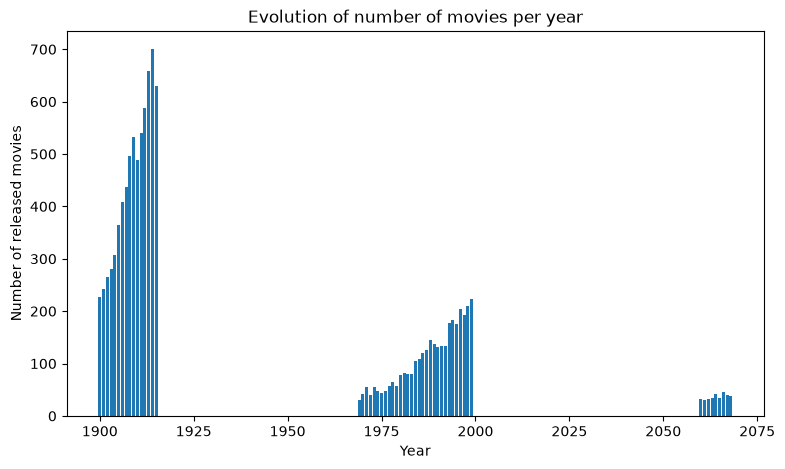

In [59]:
# plot the extracted results

# set the figure
plt.figure(figsize=(9, 5))

# set the title
plt.title('Evolution of number of movies per year')

# set the label on x and y axis
plt.xlabel('Year')
plt.ylabel('Number of released movies')

# generate the plot
plt.bar(x, y)

# display
plt.show()

<li></li>

### Evolution of popularity per decade


In [60]:
# prepare the dataset for plotting

# make a copy of clean dataset
df1 = df.copy(deep=True)

# create a column for decades
df1['decade'] = df1['release_date'].dt.year // 10 * 10

# remove the top popularity driver (above 5) to have a better visualization
df1 = df1[df1['popularity'] < 5]

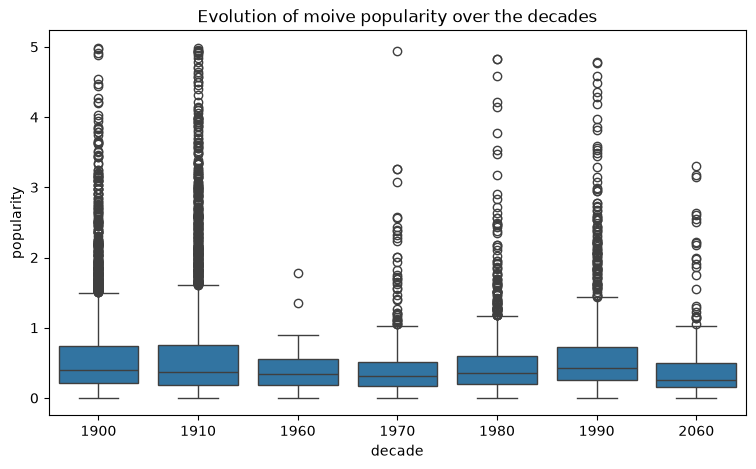

In [61]:
# plot the results 

# set the figure 
plt.figure(figsize=(9, 5))

# set the title
plt.title('Evolution of moive popularity over the decades')

# generate the plot
sns.boxplot(x=df1['decade'], y=df1['popularity'])

# display
plt.show()

<li></li>

### Top 3 movie budgets for decade


In [62]:
# make a copy of clean dataset
df1 = df.copy(deep=True)

# create a column for decades
df1['decade'] = df1['release_date'].dt.year // 10 * 10

# create a list of top 3 movie budget rows per decade
top3 = df1.groupby('decade')['budget_adj'].nlargest(3).index
top3_year, top3_rows = zip(*top3)

# filter the dataset
df1 = df1.loc[list(top3_rows)]

# display results
for i in range(df1.decade.min(), df1.decade.max() + 10, 10):
    print("Top 3 movie budget during decade " + str(i))
    display(df1[df1['decade']==i])


Top 3 movie budget during decade 1900


,popularity,original_title,cast,director,runtime,genres,production_companies,release_date,vote_count,vote_average,budget_adj,revenue_adj,decade
7387,4.965391,Pirates of the Caribbean: At World's End,Johnny Depp|Orlando Bloom|Keira Knightley|Geof...,Gore Verbinski,169,Adventure|Fantasy|Action,Walt Disney Pictures|Jerry Bruckheimer Films|S...,1907-05-19,2626,6.8,315500574,1010653507,1900
6570,1.957331,Superman Returns,Brandon Routh|Kevin Spacey|Kate Bosworth|James...,Bryan Singer,154,Adventure|Fantasy|Action|Science Fiction,DC Comics|Legendary Pictures|Warner Bros.|Bad ...,1906-06-28,834,5.3,292050672,423020463,1900
7394,2.520912,Spider-Man 3,Tobey Maguire|Kirsten Dunst|James Franco|Thoma...,Sam Raimi,139,Fantasy|Action|Adventure,Columbia Pictures|Laura Ziskin Productions|Mar...,1907-05-01,2083,5.8,271330494,936901700,1900


Top 3 movie budget during decade 1910


,popularity,original_title,cast,director,runtime,genres,production_companies,release_date,vote_count,vote_average,budget_adj,revenue_adj,decade
2244,0.250540,The Warrior's Way,Kate Bosworth|Jang Dong-gun|Geoffrey Rush|Dann...,Sngmoo Lee,100,Adventure|Fantasy|Action|Western|Thriller,Boram Entertainment Inc.,1910-12-02,74,6.4,425000000,11087569,1910
3375,4.955130,Pirates of the Caribbean: On Stranger Tides,Johnny Depp|PenÃ©lope Cruz|Geoffrey Rush|Ian M...,Rob Marshall,136,Adventure|Action|Fantasy,Walt Disney Pictures|Jerry Bruckheimer Films|M...,1911-05-11,3180,6.3,368371256,990417500,1910
1929,2.865684,Tangled,Zachary Levi|Mandy Moore|Donna Murphy|Ron Perl...,Nathan Greno|Byron Howard,100,Animation|Family,Walt Disney Pictures|Walt Disney Animation Stu...,1910-11-24,2019,7.3,260000000,591794936,1910


Top 3 movie budget during decade 1920


,popularity,original_title,cast,director,runtime,genres,production_companies,release_date,vote_count,vote_average,budget_adj,revenue_adj,decade


... (24 outputs left out)

Top 3 movie budget during decade 2050


,popularity,original_title,cast,director,runtime,genres,production_companies,release_date,vote_count,vote_average,budget_adj,revenue_adj,decade


Top 3 movie budget during decade 2060


,popularity,original_title,cast,director,runtime,genres,production_companies,release_date,vote_count,vote_average,budget_adj,revenue_adj,decade
10443,0.804533,Cleopatra,Elizabeth Taylor|Richard Burton|Rex Harrison|R...,Joseph L. Mankiewicz|Rouben Mamoulian|Darryl F...,248,Drama|History|Romance,Twentieth Century Fox Film Corporation|MCL Fil...,2063-06-12,68,6.3,221544381,411190358,2060
10409,0.485288,The Dirty Dozen,Lee Marvin|Ernest Borgnine|Charles Bronson|Jim...,Robert Aldrich,150,Action|Adventure|War,Metro-Goldwyn-Mayer (MGM)|Seven Arts Pictures|MKH,2067-06-15,168,7.2,163419093,296115397,2060
10716,0.146033,The Greatest Story Ever Told,Max von Sydow|Michael Anderson Jr.|Carroll Bak...,George Stevens,199,Drama|History,George Stevens Productions,2065-02-15,13,5.7,138411273,83046764,2060


### Percentage of profit-making movie per decade

In [63]:
# make a copy of clean dataset
df1 = df1.copy(deep=True)

# create a column for decades
df1['decade'] = df1['release_date'].dt.year // 10 * 10

# create a column that informs about profit-making or not
df1['profit_making'] = np.where(df1['revenue_adj'] > df1['budget_adj'], True, False)

# group by decade and boolean and extract percentage of profit-making movies
df2 = df1.groupby(['decade', 'profit_making']).agg({'profit_making': 'count'},)
Tot = df1.groupby(['decade']).agg({'profit_making': 'count'})
df3 = df2.div(Tot, level='decade') * 100

# pass the index decade and boolean to columns
df3 = df3.assign(profit = df3.index.get_level_values('profit_making'))
df3 = df3.assign(decade = df3.index.get_level_values('decade'))

# only keep rows with profit-making True
df3 = df3[df3['profit']==True]


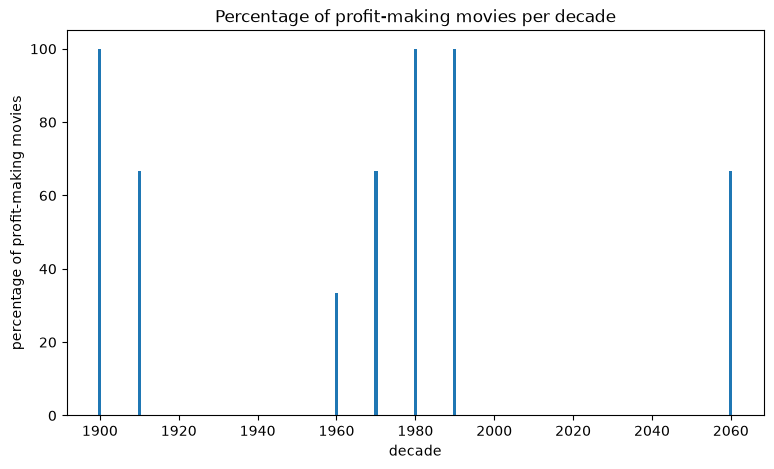

In [64]:
# plot results
plt.figure(figsize=(9, 5))
plt.bar(df3['decade'], df3['profit_making'])

# set title
plt.title('Percentage of profit-making movies per decade')

# set x and y labels
plt.xlabel('decade')
plt.ylabel('percentage of profit-making movies')

# display results
plt.show()

<li></li>

### Movie with highest and lowest profit

In [65]:
def high_low(df, column):
    max_val_loc = df[column].idxmax()
    df_max = pd.DataFrame(df.loc[max_val_loc])
    min_val_loc = df[column].idxmin()
    df_min = pd.DataFrame(df.loc[min_val_loc])
    df_max = df_max.join(df_min)
    display(df_max)
    return

df1 = df.copy(deep=True)
df1['profit'] = df1['revenue_adj'] - df1['budget_adj']
high_low(df1, 'profit')

,1329,2244
popularity,12.037933,0.25054
original_title,Star Wars,The Warrior's Way
cast,Mark Hamill|Harrison Ford|Carrie Fisher|Peter ...,Kate Bosworth|Jang Dong-gun|Geoffrey Rush|Dann...
director,George Lucas,Sngmoo Lee
runtime,121,100
genres,Adventure|Action|Science Fiction,Adventure|Fantasy|Action|Western|Thriller
production_companies,Lucasfilm|Twentieth Century Fox Film Corporation,Boram Entertainment Inc.
release_date,1977-03-20 00:00:00,1910-12-02 00:00:00
vote_count,4428,74
vote_average,7.9,6.4


### Movie with highest and lowest popularity

In [67]:
df1 = df.copy(deep=True)
high_low(df1, 'popularity')

,0,6181
popularity,32.985763,0.000065
original_title,Jurassic World,"North and South, Book I"
cast,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,Patrick Swayze|Philip Casnoff|Kirstie Alley|Ge...
director,Colin Trevorrow,NaN
runtime,124,561
genres,Action|Adventure|Science Fiction|Thriller,Drama|History|Western
production_companies,Universal Studios|Amblin Entertainment|Legenda...,NaN
release_date,1915-06-09 00:00:00,1985-11-03 00:00:00
vote_count,5562,17
vote_average,6.5,6.0


### Movie with highest and lowest average vote results

In [68]:
high_low(df1, 'vote_average')

,3894,7772
popularity,0.006925,0.12112
original_title,The Story of Film: An Odyssey,Transmorphers
cast,Mark Cousins|Jean-Michel Frodon|Cari Beauchamp...,Matthew Wolf|Amy Weber|Shaley Scott|Eliza Swen...
director,Mark Cousins,Leigh Scott
runtime,900,86
genres,Documentary,Action|Adventure|Science Fiction
production_companies,NaN,"Asylum, The"
release_date,1911-09-03 00:00:00,1907-06-26 00:00:00
vote_count,14,10
vote_average,9.2,1.5


### Evolution of genre distribution over the years

In [69]:
def multi_value(df, column, separator):
    big_chain = df[column].str.cat(sep=separator)
    ser = pd.Series(big_chain.split(separator))
    return ser




In [70]:
def over_the_year(df, col):
    rows = []
    for year in range(df['release_date'].dt.year.min(), df['release_date'].dt.year.max() + 1):
        df1 = df[df['release_date'].dt.year == year]
        ser = multi_value(df1, col, '|')
        rows.append(pd.DataFrame({
            col: ser,
            'year': year
        }))
    return pd.concat(rows, ignore_index=True)


    

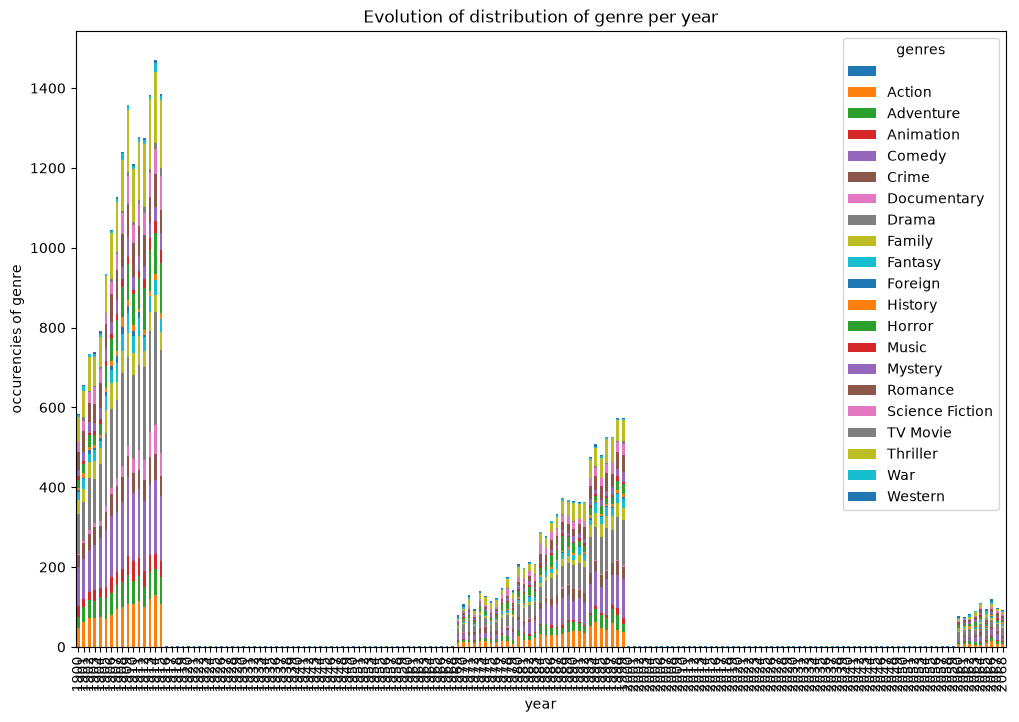

In [71]:
df_oty = over_the_year(df, 'genres')

df_oty.groupby(['year', 'genres']).size().unstack().plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Evolution of distribution of genre per year')
plt.xlabel('year')
plt.ylabel('occurencies of genre')
plt.show()

<li></li>

### Correlations to revenue

<Figure size 900x500 with 0 Axes>

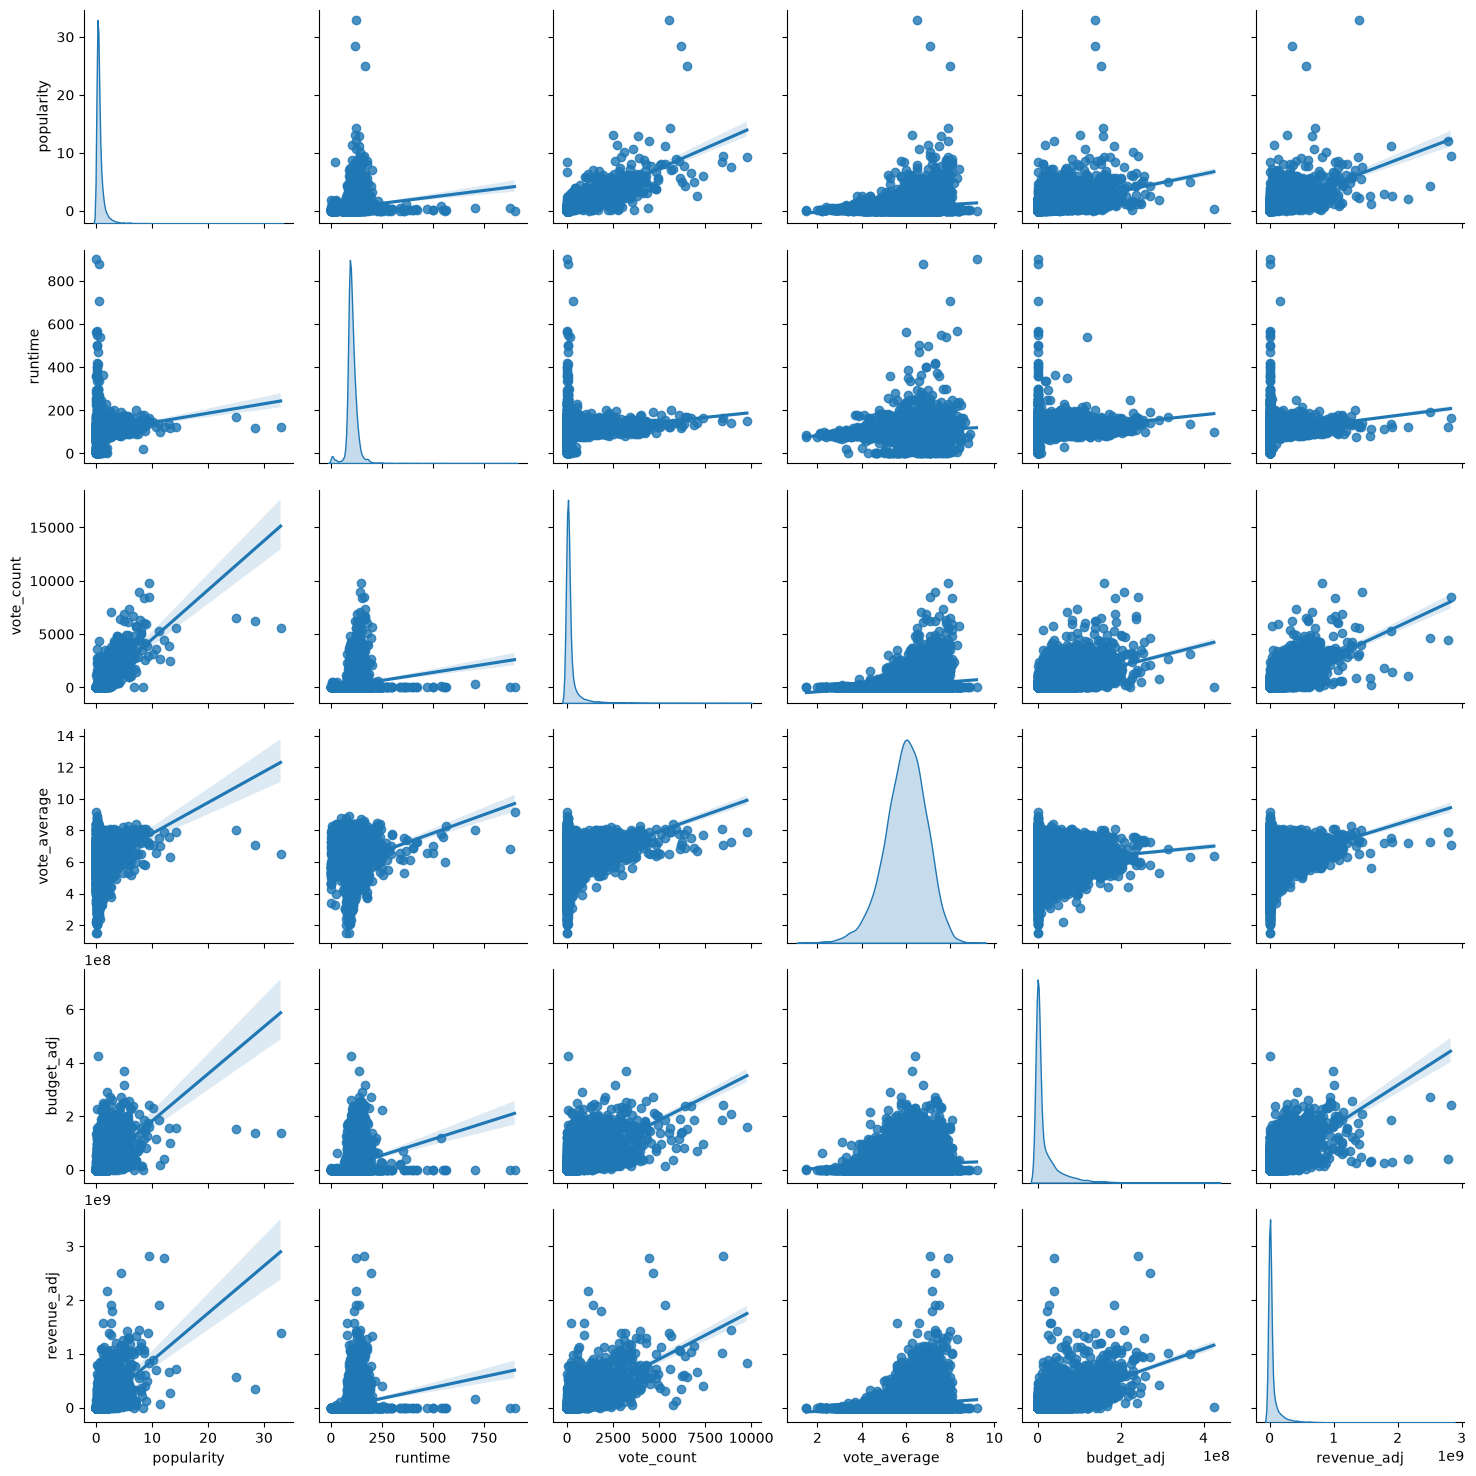

In [72]:
plt.figure(figsize=(9, 5))
sns.pairplot(df, kind='reg', diag_kind="kde")
plt.show()

<li></li>


## Conclusions
